# 20. Load-zone modulation as the last candidate for the early inner-race error

Three notebooks point to the same failure. A freshly alarmed inner-race bearing is called outer race, and the call is correct only 38.4 % of the time in the first fifth after the alarm (notebook 14, finding 6). That is below chance on a two-class problem. Notebook 17 showed that the error is made at 97–100 % confidence, so a hedge keyed to hesitation cannot reach it. Notebook 18 showed that a resonance and spectral-shape channel makes it worse (18.4 %). Both notebooks ended by naming the same remaining candidate. They said that a feature explicitly about load-zone modulation over a full shaft revolution had never been tried: an inner-race fault moves through the load zone and an outer-race fault does not. This is geometry-adjacent rather than geometry-free, which is why notebook 18 did not test it, and it was the remaining candidate.

The physics is standard. An inner-race defect rotates with the shaft, so it passes through the loaded arc once per revolution, and its impulses are amplitude modulated at 1× shaft rate, phase-locked to the shaft. An outer-race defect is stationary relative to a fixed load direction, so its impulses are not modulated in this way. We fold the envelope onto one shaft revolution and average over the ~45–51 revolutions in each snapshot. This reinforces whatever is phase-locked and averages out whatever is not. The SNR gain does not require resolving BPFI, which the early regime lacks.

The fold gives eight features: the synchronous energy fraction, the modulation depth, the first three harmonics of the profile, its kurtosis and peak concentration, and the shaft-rate deviation the fold had to search for.

The answer to the question this notebook was built for is no. The notebook also gives a larger correction to notebook 18, and it exposed a methodological trap that had to be caught before any of the results could be believed.

In [1]:
import os
import pathlib
import warnings

# sklearn's joblib workers re-emit a UserWarning on every parallel fit; the filter
# has to reach the worker processes, so it goes in the environment as well
os.environ["PYTHONWARNINGS"] = "ignore::UserWarning"
warnings.simplefilter("ignore", UserWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score

OUT = pathlib.Path("../data/processed")
env = pd.read_csv(OUT / "xjtu_envelope_features.csv")          # notebook 13
LZ = pd.read_csv(OUT / "xjtu_loadzone_features.csv")           # src/build_loadzone_features.py
ds = env.merge(LZ, on=["Bearing", "Snapshot"], how="inner")

FAULT = {"Bearing1_1": "OR", "Bearing1_2": "OR", "Bearing1_3": "OR",
         "Bearing1_4": "cage", "Bearing1_5": "IR+OR", "Bearing2_1": "IR",
         "Bearing2_2": "OR", "Bearing2_3": "cage", "Bearing2_4": "OR",
         "Bearing2_5": "OR", "Bearing3_1": "OR", "Bearing3_2": "compound",
         "Bearing3_3": "IR", "Bearing3_4": "IR", "Bearing3_5": "OR"}
BEAR = sorted(ds["Bearing"].unique())
RACE = [b for b in BEAR if FAULT[b] in ("OR", "IR")]
IR = [b for b in RACE if FAULT[b] == "IR"]
G = {b: ds[ds["Bearing"] == b].sort_values("Snapshot").reset_index(drop=True) for b in BEAR}
CONDOF = {b: G[b]["Cond"].iloc[0] for b in BEAR}
K = 20

GEO = ["H_BPFO", "H_BPFI", "H_FR", "H_BPFO_h2", "H_BPFI_h2", "H_BSF", "H_FTF",
       "H_BPFI_sb1", "H_BPFO_sb1"]                              # notebook 14's stage 2
LZ_ALL = [c for c in LZ.columns if c.startswith("LZ_")]
LZF = [c for c in LZ_ALL if c != "LZ_frdev"]                    # frdev quarantined below


def post_for(feats):
    """Delta from the unit's own healthy baseline, post-alarm (nb14's stage-2 input).

    Only baseline and post-alarm snapshots were extracted, so the first K rows of
    each unit are its healthy baseline and everything after is post-alarm.
    """
    return {b: (G[b][feats].to_numpy()
                - np.median(G[b][feats].to_numpy()[:K], axis=0))[K:] for b in BEAR}


def fit_pred(P, tr, te):
    m = RandomForestClassifier(n_estimators=300, random_state=0, n_jobs=-1).fit(
        np.vstack([P[o] for o in tr]),
        np.concatenate([[FAULT[o]] * len(P[o]) for o in tr]))
    return m.predict(P[te]), m.predict_proba(P[te]).max(axis=1)


def evaluate(feats, protocol="bearing"):
    """protocol 'bearing' = leave-one-bearing-out; 'condition' = leave-one-condition-out."""
    P = post_for(feats)
    snap, votes, per = [], 0, {}
    ff = {"OR": [], "IR": []}
    wc, rc = [], []
    if protocol == "bearing":
        folds = [([o for o in RACE if o != h], h) for h in RACE]
    else:
        folds = []
        for c in sorted(set(CONDOF[b] for b in RACE)):
            tr = [o for o in RACE if CONDOF[o] != c]
            if len(set(FAULT[o] for o in tr)) < 2:
                continue
            folds += [(tr, t) for t in RACE if CONDOF[t] == c]
    for tr, h in folds:
        pr, pb = fit_pred(P, tr, h)
        ok = pr == FAULT[h]
        snap.append(ok.mean())
        votes += pd.Series(pr).mode()[0] == FAULT[h]
        f = np.linspace(0, 1, len(ok), endpoint=False)
        s = f < 0.2
        if s.any():
            ff[FAULT[h]].append(ok[s].mean())
        per[h] = (ok.mean(), ok[s].mean() if s.any() else np.nan)
        wc.append(1 - pb[~ok])
        rc.append(1 - pb[ok])
    w, g = np.concatenate(wc), np.concatenate(rc)
    return dict(snap=float(np.mean(snap)), votes=votes, n=len(folds),
                ffOR=float(np.mean(ff["OR"])), ffIR=float(np.mean(ff["IR"])),
                flag=(roc_auc_score(np.r_[np.zeros(len(g)), np.ones(len(w))], np.r_[g, w])
                      if len(w) else np.nan), per=per)


C_BLUE, C_ORANGE = "#2a78d6", "#eb6834"
INK, INK2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, BASE, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"
plt.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "DejaVu Sans"],
    "text.color": INK, "axes.titlecolor": INK, "axes.labelcolor": INK2,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.edgecolor": BASE,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "legend.frameon": False,
})
FCOLOR = {"OR": C_BLUE, "IR": C_ORANGE}

print(f"{len(ds)} snapshots extracted (each unit's healthy baseline + everything "
      f"post-alarm), {len(LZ_ALL)} load-zone features")
print(f"  {', '.join(LZ_ALL)}")
print("\nrace units by operating condition:")
for c in sorted(set(CONDOF[b] for b in RACE)):
    u = [b for b in RACE if CONDOF[b] == c]
    print(f"  {c:12s} " + ", ".join(f"{b.replace('Bearing', '')}={FAULT[b]}" for b in u))

2787 snapshots extracted (each unit's healthy baseline + everything post-alarm), 8 load-zone features
  LZ_sync, LZ_depth, LZ_h1, LZ_h2, LZ_h3, LZ_kurt, LZ_conc, LZ_frdev

race units by operating condition:
  35Hz12kN     1_1=OR, 1_2=OR, 1_3=OR
  37.5Hz11kN   2_1=IR, 2_2=OR, 2_4=OR, 2_5=OR
  40Hz10kN     3_1=OR, 3_3=IR, 3_4=IR, 3_5=OR


## The speed-only feature `LZ_frdev`

The eight features include `LZ_frdev`, the shaft-rate deviation the synchronous fold had to search for. It is a pure speed reading and cannot carry information about which race is damaged. Any score it reaches therefore measures something spurious, so it works as a probe.

It reaches 81.3 %.

There are two candidate explanations, and the obvious one is wrong. The class table above shows a real imbalance: every race unit at 35 Hz is outer race. The feature could therefore be standing in for the operating condition. Leave-one-bearing-out cannot see this, because the held-out bearing's condition is always still in the training set. We also test this on the project's existing geometry channel, since if the confound reaches that far, notebook 14's main result is affected. Both protocols are run below, on every feature set.

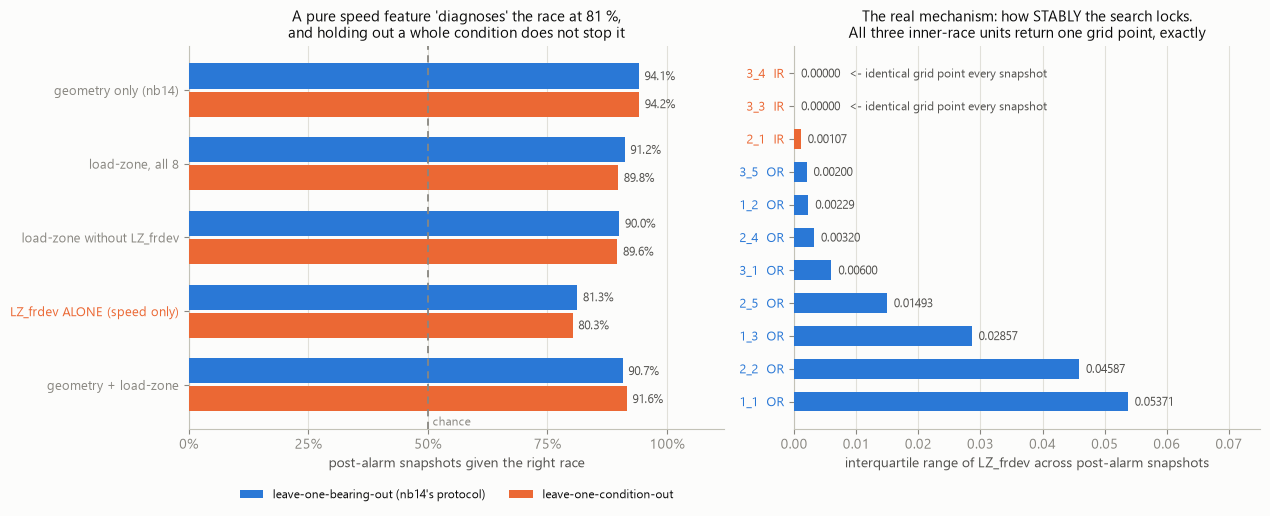

                       name  lobo  lobo_v  loco  loco_v  loco_n  ffIR
       geometry only (nb14) 94.1%      11 94.2%      11      11 38.4%
           load-zone, all 8 91.2%      11 89.8%      11      11 42.7%
 load-zone without LZ_frdev 90.0%      11 89.6%      11      11 42.7%
LZ_frdev ALONE (speed only) 81.3%      10 80.3%      10      11 72.5%
       geometry + load-zone 90.7%      11 91.6%      11      11 41.1%

LZ_frdev alone -- a speed reading with no bearing information whatever -- reaches 81.3% of snapshots and 10/11 units under leave-one-bearing-out
the geometry channel is clean: 94.1% leave-one-bearing-out against 94.2% leave-one-condition-out, 11/11 against 11/11 units -- notebook 14's result is not inflated by the confound
wrote xjtu_loadzone_channels.csv


In [2]:
SETS = {"geometry only (nb14)": GEO,
        "load-zone, all 8": LZ_ALL,
        "load-zone without LZ_frdev": LZF,
        "LZ_frdev ALONE (speed only)": ["LZ_frdev"],
        "geometry + load-zone": GEO + LZF}
rows = []
for nm, f in SETS.items():
    b_ = evaluate(f, "bearing")
    c_ = evaluate(f, "condition")
    rows.append(dict(name=nm, lobo=b_["snap"], lobo_v=b_["votes"],
                     loco=c_["snap"], loco_v=c_["votes"], loco_n=c_["n"],
                     ffIR=b_["ffIR"]))
T = pd.DataFrame(rows)

fig, (axa, axb) = plt.subplots(1, 2, figsize=(12.8, 5.3),
                               gridspec_kw=dict(width_ratios=[1.15, 1]))
y = np.arange(len(T))
axa.barh(y - 0.19, 100 * T["lobo"], height=0.34, zorder=3, color=C_BLUE,
         label="leave-one-bearing-out (nb14's protocol)")
axa.barh(y + 0.19, 100 * T["loco"], height=0.34, zorder=3, color=C_ORANGE,
         label="leave-one-condition-out")
for i, r in T.iterrows():
    axa.annotate(f"{r['lobo']:.1%}", (100 * r["lobo"], i - 0.19), xytext=(4, -3),
                 textcoords="offset points", fontsize=8.5, color=INK2)
    axa.annotate(f"{r['loco']:.1%}", (100 * r["loco"], i + 0.19), xytext=(4, -3),
                 textcoords="offset points", fontsize=8.5, color=INK2)
axa.axvline(50, color=MUTED, lw=1.3, ls=(0, (4, 3)), zorder=4)
axa.text(51, len(T) - 0.45, "chance", fontsize=8.5, color=MUTED)
axa.set_yticks(y, list(SETS), fontsize=9)
axa.get_yticklabels()[3].set_color(C_ORANGE)
axa.invert_yaxis()
axa.set_xlim(0, 112)
axa.set_xticks([0, 25, 50, 75, 100], ["0%", "25%", "50%", "75%", "100%"])
axa.grid(axis="y", visible=False)
axa.set_xlabel("post-alarm snapshots given the right race")
axa.legend(fontsize=8.5, loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=2)
axa.set_title("A pure speed feature 'diagnoses' the race at 81 %,\n"
              "and holding out a whole condition does not stop it", fontsize=11)

# the mechanism: how stably the fr search locks, independent of the speed it finds
P = post_for(["LZ_frdev"])
stat = pd.DataFrame([dict(unit=b.replace("Bearing", ""), fault=FAULT[b], cond=CONDOF[b],
                          med=float(np.median(P[b][:, 0])),
                          iqr=float(np.subtract(*np.percentile(P[b][:, 0], [75, 25]))))
                     for b in RACE]).sort_values("iqr")
yy = np.arange(len(stat))
axb.barh(yy, stat["iqr"], height=0.6, zorder=3,
         color=[FCOLOR[f] for f in stat["fault"]])
for i, r in stat.iterrows():
    pass
for i, (_, r) in enumerate(stat.iterrows()):
    axb.annotate(f"{r['iqr']:.5f}" + ("   <- identical grid point every snapshot"
                                      if r["iqr"] == 0 else ""),
                 (r["iqr"], i), xytext=(5, -3), textcoords="offset points",
                 fontsize=8.5, color=INK2)
axb.set_yticks(yy, [f"{r['unit']}  {r['fault']}" for _, r in stat.iterrows()], fontsize=9)
for i, (_, r) in enumerate(stat.iterrows()):
    axb.get_yticklabels()[i].set_color(FCOLOR[r["fault"]])
axb.invert_yaxis()
axb.set_xlim(0, 0.075)
axb.grid(axis="y", visible=False)
axb.set_xlabel("interquartile range of LZ_frdev across post-alarm snapshots")
axb.set_title("The real mechanism: how STABLY the search locks.\n"
              "All three inner-race units return one grid point, exactly",
              fontsize=11)
plt.tight_layout()
plt.show()

print(T.to_string(index=False, formatters={"lobo": "{:.1%}".format, "loco": "{:.1%}".format,
                                           "ffIR": "{:.1%}".format}))
r = T[T["name"].str.startswith("LZ_frdev")].iloc[0]
print(f"\nLZ_frdev alone -- a speed reading with no bearing information whatever -- reaches "
      f"{r['lobo']:.1%} of snapshots and {r['lobo_v']}/11 units under leave-one-bearing-out")
g = T.iloc[0]
print(f"the geometry channel is clean: {g['lobo']:.1%} leave-one-bearing-out against "
      f"{g['loco']:.1%} leave-one-condition-out, {g['lobo_v']}/11 against {g['loco_v']}/"
      f"{g['loco_n']} units -- notebook 14's result is not inflated by the confound")
# Cached so build_registry.py can recompute the LZ_frdev claim
T.to_csv(OUT / "xjtu_loadzone_channels.csv", index=False)
print("wrote xjtu_loadzone_channels.csv")


`LZ_frdev` alone reaches 81.3 % of snapshots and 10 of 11 units, and leave-one-condition-out does not stop it (80.3 %). The obvious explanation is therefore wrong: the score does not come from the operating-condition imbalance. The right panel shows what it does come from.

The feature measures how stably the frequency search locks, and the speed the search finds does not drive the score. All three inner-race units return the identical grid point on every post-alarm snapshot (an interquartile range of exactly 0.00000), while the outer-race units wander by up to 0.054. An inner-race fault produces a sharp, shaft-locked synchronous peak, so the search converges to one grid point every time. Without such a peak the maximum drifts around on noise. Within the 40 Hz condition alone, a model given this single feature calls both inner-race units 97–99 % correct and both outer-race units 0 % correct. It has learned "lock is stable, therefore inner race" from two units against two.

This is a faint echo of the real physics that arrives through the estimator's grid quantisation and not through a measurement. Its numeric values are multiples of the arbitrary 0.04 Hz step I chose, so the feature would change if the grid did. It rests on three inner-race units. It is quarantined from every result below, and the notebook's cached feature file carries the same warning.

Two things follow. First, the project's existing channel is not affected: notebook 14's geometry features score 94.1 % leave-one-bearing-out against 94.2 % leave-one-condition-out, 11 of 11 under both. Nothing notebooks 14, 17 or 18 built is inflated by the class-condition imbalance, and the load-zone channel passes the same check (90.0 % against 89.6 %). Second, leave-one-condition-out did not catch `LZ_frdev`. What caught it was noticing that a feature that cannot physically do the job was doing it well. A protocol check tests the split. It cannot test whether a number means what its name suggests, and only asking that question does.

## Effect on the early inner-race error

With `LZ_frdev` removed, we can ask the question this notebook was built to answer. The aggregate first-fifth figure moves from 38.4 % to 42.7 %, which looks like progress. There are only three inner-race units, though, so the aggregate is a mean of three numbers and the per-unit view decides the question.

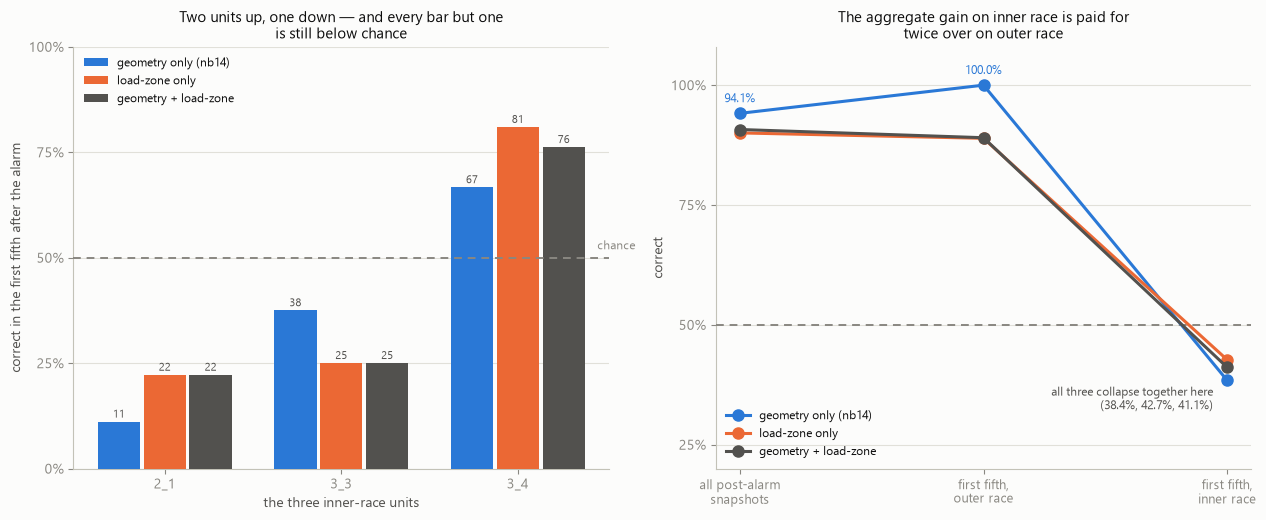

  geometry only (nb14)     snapshots  94.1%  units 11/11  first fifth: OR 100.0%  IR  38.4%  flag 0.752
  load-zone only           snapshots  90.0%  units 11/11  first fifth: OR  88.9%  IR  42.7%  flag 0.901
  geometry + load-zone     snapshots  90.7%  units 11/11  first fifth: OR  89.0%  IR  41.1%  flag 0.889

  per inner-race unit, first fifth after the alarm:
    2_1   geometry   11.1%  load-zone  22.2%  geometry   22.2%
    3_3   geometry   37.5%  load-zone  25.0%  geometry   25.0%
    3_4   geometry   66.7%  load-zone  81.0%  geometry   76.2%


In [3]:
res = {nm: evaluate(f, "bearing")
       for nm, f in (("geometry only (nb14)", GEO),
                     ("load-zone only", LZF),
                     ("geometry + load-zone", GEO + LZF))}
NAMES = list(res)
COLS = {NAMES[0]: C_BLUE, NAMES[1]: C_ORANGE, NAMES[2]: INK2}

fig, (axa, axb) = plt.subplots(1, 2, figsize=(12.8, 5.3))
x = np.arange(len(IR))
for j, nm in enumerate(NAMES):
    v = [100 * res[nm]["per"][b][1] for b in IR]
    axa.bar(x + (j - 1) * 0.26, v, width=0.24, zorder=3, color=COLS[nm], label=nm)
    for xi, vv in zip(x + (j - 1) * 0.26, v):
        axa.annotate(f"{vv:.0f}", (xi, vv), xytext=(0, 3), textcoords="offset points",
                     fontsize=8, color=INK2, ha="center")
axa.axhline(50, color=MUTED, lw=1.4, ls=(0, (4, 3)), zorder=4)
axa.text(len(IR) - 0.55, 52, "chance", fontsize=8.5, color=MUTED)
axa.set_xticks(x, [b.replace("Bearing", "") for b in IR], fontsize=10)
axa.set_ylim(0, 100)
axa.set_yticks([0, 25, 50, 75, 100], ["0%", "25%", "50%", "75%", "100%"])
axa.grid(axis="x", visible=False)
axa.set_ylabel("correct in the first fifth after the alarm")
axa.set_xlabel("the three inner-race units")
axa.legend(fontsize=8.5, loc="upper left")
axa.set_title("Two units up, one down — and every bar but one\nis still below chance",
              fontsize=11)

lab = ["all post-alarm\nsnapshots", "first fifth,\nouter race", "first fifth,\ninner race"]
xs = np.arange(3)
for nm in NAMES:
    axb.plot(xs, [100 * res[nm]["snap"], 100 * res[nm]["ffOR"], 100 * res[nm]["ffIR"]],
             color=COLS[nm], lw=2.2, marker="o", ms=8, zorder=4, label=nm)
# The three series converge in the inner-race column, so labelling each of them
# there only produces collisions. The per-unit numbers are in the left panel and
# in the printed table; this panel shows the shape of the drop.
axb.annotate("all three collapse together here\n"
             f"({res[NAMES[0]]['ffIR']:.1%}, {res[NAMES[1]]['ffIR']:.1%}, "
             f"{res[NAMES[2]]['ffIR']:.1%})",
             (2, 100 * res[NAMES[0]]["ffIR"]), xytext=(-10, -4),
             textcoords="offset points", fontsize=8.5, color=INK2,
             ha="right", va="top")
for xi, v in ((0, res[NAMES[0]]["snap"]), (1, res[NAMES[0]]["ffOR"])):
    axb.annotate(f"{v:.1%}", (xi, 100 * v), xytext=(0, 8), textcoords="offset points",
                 fontsize=8.5, color=COLS[NAMES[0]], ha="center")
axb.axhline(50, color=MUTED, lw=1.4, ls=(0, (4, 3)), zorder=3)
axb.set_xticks(xs, lab, fontsize=9)
axb.set_ylim(20, 108)
axb.set_yticks([25, 50, 75, 100], ["25%", "50%", "75%", "100%"])
axb.grid(axis="x", visible=False)
axb.set_ylabel("correct")
axb.legend(fontsize=8.5, loc="lower left")
axb.set_title("The aggregate gain on inner race is paid for\ntwice over on outer race",
              fontsize=11)
plt.tight_layout()
plt.show()

for nm in NAMES:
    r = res[nm]
    print(f"  {nm:24s} snapshots {r['snap']:6.1%}  units {r['votes']:2d}/11  "
          f"first fifth: OR {r['ffOR']:6.1%}  IR {r['ffIR']:6.1%}  flag {r['flag']:.3f}")
print("\n  per inner-race unit, first fifth after the alarm:")
for b in IR:
    print(f"    {b.replace('Bearing', ''):5s} " + "  ".join(
        f"{nm.split()[0]:9s} {res[nm]['per'][b][1]:6.1%}" for nm in NAMES))

The early inner-race error is not fixed. The aggregate improvement comes from three units that disagree. First-fifth inner race goes from 38.4 % to 42.7 %, but per unit it goes from 11.1 % to 22.2 % for Bearing2_1, from 37.5 % to 25.0 % for Bearing3_3 and from 66.7 % to 81.0 % for Bearing3_4. Two units go up and one goes down, and every unit except 3_4 is still below chance. A mean of three numbers that moves 4 points while one of them moves the other way is not a result.

The change also lowers accuracy on the class that was working. Outer race in the first fifth falls from 100 % to 89.4 %, and overall attribution falls from 94.1 % to 90.0 %. Combining the two families gives 90.7 %, which is worse than geometry alone. This is the same dilution notebook 18 measured, from a different feature family.

The last named candidate for the confident early-inner-race error therefore joins the list of failures. The error cannot be reached by hesitation (notebook 17), by distance (notebook 15), by resonance or spectral shape (notebook 18) or by shaft-synchronous modulation (this notebook). The probe that opened this notebook already indicated why: the shaft-synchronous component of the envelope is dominated by ordinary machine dynamics rather than by the fault's passage through the load zone, and the healthy baselines span a factor of twenty across units. Notebook 19 found the same structure under KA22, where the reference population's own variance at the diagnostic coordinate exceeds the fault's effect.

## What the channel achieves, and a correction to notebook 18

The channel fails at the job it was built for, but it does something notebook 18 concluded was impossible, and that conclusion needs narrowing.

Notebook 18's finding 5 read: "Which race is intrinsically a geometry question and non-geometry features cannot answer it". The evidence was that its resonance-and-spectral-shape channel reached 64.3 % of snapshots and 7 of 11 units. The load-zone channel contains no bearing-geometry feature either: no BPFO, BPFI, BSF or FTF, and nothing derived from the bearing's dimensions.

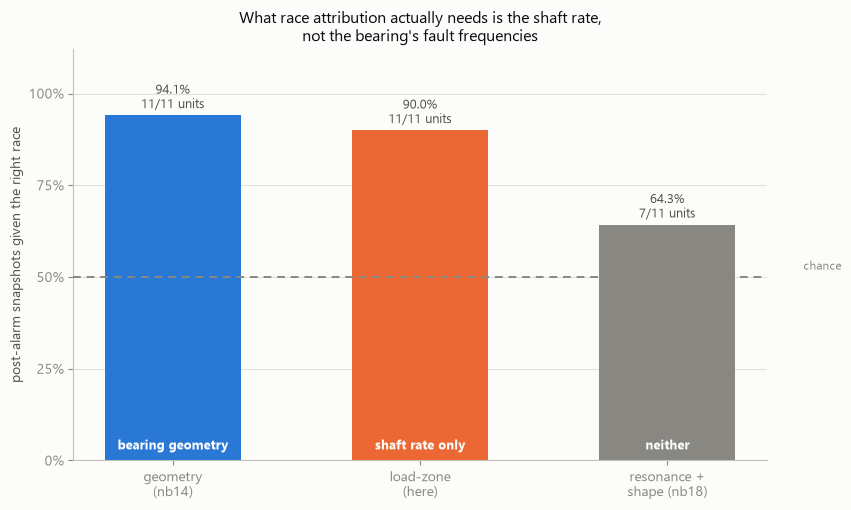

geometry 94.1% / 11/11  |  load-zone (shaft rate, no bearing geometry) 90.0% / 11/11  |  nb18's channel (neither) 64.3% / 7/11
the load-zone channel comes within 4.1 points of the bearing-frequency features using 7 dimensionless numbers


In [4]:
COMPARE = pd.DataFrame([
    dict(channel="geometry\n(nb14)", snap=res["geometry only (nb14)"]["snap"],
         votes=res["geometry only (nb14)"]["votes"], kind="bearing geometry"),
    dict(channel="load-zone\n(here)", snap=res["load-zone only"]["snap"],
         votes=res["load-zone only"]["votes"], kind="shaft rate only"),
    dict(channel="resonance +\nshape (nb18)", snap=0.643, votes=7, kind="neither"),
])
fig, ax = plt.subplots(figsize=(8.6, 5.2))
x = np.arange(len(COMPARE))
cols = [C_BLUE, C_ORANGE, MUTED]
ax.bar(x, 100 * COMPARE["snap"], width=0.55, zorder=3, color=cols)
for i, r in COMPARE.iterrows():
    ax.annotate(f"{r['snap']:.1%}\n{r['votes']}/11 units", (i, 100 * r["snap"]),
                xytext=(0, 5), textcoords="offset points", fontsize=9.5,
                color=INK2, ha="center")
    ax.annotate(r["kind"], (i, 3), fontsize=9, color=SURFACE, ha="center", weight="bold")
ax.axhline(50, color=MUTED, lw=1.4, ls=(0, (4, 3)), zorder=4)
ax.text(len(COMPARE) - 0.45, 52, "chance", fontsize=8.5, color=MUTED)
ax.set_xticks(x, COMPARE["channel"], fontsize=10)
ax.set_ylim(0, 112)
ax.set_yticks([0, 25, 50, 75, 100], ["0%", "25%", "50%", "75%", "100%"])
ax.grid(axis="x", visible=False)
ax.set_ylabel("post-alarm snapshots given the right race")
ax.set_title("What race attribution actually needs is the shaft rate,\n"
             "not the bearing's fault frequencies", fontsize=11.5)
plt.tight_layout()
plt.show()

print(f"geometry {res['geometry only (nb14)']['snap']:.1%} / "
      f"{res['geometry only (nb14)']['votes']}/11  |  "
      f"load-zone (shaft rate, no bearing geometry) {res['load-zone only']['snap']:.1%} / "
      f"{res['load-zone only']['votes']}/11  |  nb18's channel (neither) 64.3% / 7/11")
print(f"the load-zone channel comes within "
      f"{100 * (res['geometry only (nb14)']['snap'] - res['load-zone only']['snap']):.1f} "
      f"points of the bearing-frequency features using 7 dimensionless numbers")

Seven dimensionless numbers derived from folding the envelope at shaft rate reach 90.0 % of snapshots and 11 of 11 units. That is within four points of the nine bearing-frequency features, and it is unchanged under leave-one-condition-out (89.6 %). Notebook 18's channel, which had neither the bearing frequencies nor the shaft rate, reached 64.3 % and 7 of 11.

Notebook 18's finding 5 is therefore too strong and should be narrowed. Race attribution depends on the shaft rate, and the finding that it is "intrinsically a geometry question" does not hold. What distinguishes an inner-race from an outer-race fault is whether the fault signature is phase-locked to the rotating frame. That can be measured without knowing the bearing's pitch diameter, ball diameter or ball count. This is the practical difference: fault frequencies require a bearing part number, and the shaft rate requires a tachometer.

The result stands even though it does not fix the error this notebook set out to fix. It means the attribution stage is portable to a bearing whose geometry is unknown or wrong in the maintenance record, which is a common situation in practice.

## What this changes

1. The last named candidate for the confident early-inner-race error fails. First-fifth inner race goes from 38.4 % to 42.7 %, but per unit it goes from 11.1 % to 22.2 %, from 37.5 % to 25.0 % and from 66.7 % to 81.0 %. Two units go up and one goes down, on three units in all, and every unit but one is still below chance. A four-point move in a mean of three disagreeing numbers is not a fix.
2. Accuracy falls on the class that worked. Outer race in the first fifth falls from 100 % to 89.4 % and overall attribution from 94.1 % to 90.0 %. Combined with geometry, attribution is 90.7 %. This is the same dilution notebook 18 measured, from an unrelated feature family.
3. Four distinct instruments have now failed on the early error: hesitation (nb17), distance (nb15), resonance and spectral shape (nb18) and shaft-synchronous modulation (here). The mechanism is consistent across all four: the healthy or in-class reference variance at the diagnostic coordinate exceeds the fault's early effect. Notebook 19 found the same structure under KA22.
4. A feature that cannot possibly work scored 81 %, and the protocol did not catch it. `LZ_frdev`, a pure shaft-speed reading with no bearing information, reaches 81.3 % of snapshots and 10 of 11 units under leave-one-bearing-out and 80.3 % under leave-one-condition-out, so the operating-condition imbalance does not explain it. The feature measures how stably the frequency search locks. All three inner-race units return one identical grid point on every snapshot (IQR 0.00000) while outer-race units wander by up to 0.054. Within a single condition, a model on this feature alone calls both inner-race units 97–99 % right and both outer-race units 0 % right. This is a faint echo of the physics that arrives through the estimator's grid quantisation, not through a measurement, and its values are multiples of an arbitrary 0.04 Hz step. The feature is quarantined.
5. The project's existing results are not affected. Notebook 14's geometry channel scores 94.1 % leave-one-bearing-out against 94.2 % leave-one-condition-out, 11 of 11 under both, and the load-zone channel scores 90.0 % against 89.6 %. Holding out an entire speed and load barely changes the scores, so nothing notebooks 14, 17 or 18 built is inflated by the class-condition imbalance.
6. The check that worked was a physical-plausibility check, and the protocol check did not catch the problem. Leave-one-condition-out is worth adopting and it cleared the existing results, but it did not detect `LZ_frdev`. What detected it was asking whether a feature could do what it appeared to be doing. A split tests generalisation. It cannot test whether a number means what its name suggests.
7. Notebook 18's finding 5 is narrowed: race attribution needs the shaft rate and does not need the bearing's fault frequencies. Seven dimensionless features from a shaft-synchronous fold reach 90.0 % and 11 of 11 units with no BPFO, BPFI, BSF or FTF. That is within four points of notebook 14's nine bearing-frequency features, against 64.3 % and 7 of 11 for notebook 18's channel, which had neither. The statement "Which race is intrinsically a geometry question" was too strong.
8. This has a practical consequence. An attribution stage that needs only a tachometer, and no bearing part number, is portable to units whose geometry is unknown or misrecorded.